# Two-Layer Recurring Tasks

**Questions:** (1) Can a two-layer learner learn a representation shared by two recurring tasks? (2) When a task returns after an absence, how fast does its error recover compared with frozen true features? (3) Does that recovery depend on how long the task was absent?

**Teacher.** 21 independent ±1 inputs. Ten lower LTUs are shared by both tasks; each fires when its ±1-weighted input sum exceeds 2, about a third of the time. Each task has its own ten upper LTUs, reading the lower units with ±1 weights and thresholded to fire about 30% of the time, and its own ±1 weights to the same ten outputs. No task ID is given, so one readout serves both tasks and must re-adapt after every switch. Targets have Gaussian noise with standard deviation 1, so the RMSE floor is 1.

**Learner.** 21 inputs → 15 LTUs → 30 LTUs → 10 linear outputs; 10 → 20 units suffice to represent both teachers. Hidden units are standardized, h = (b − m) / √max(m(1 − m), 0.01), where m is a running firing rate (rate 0.001). The backward pass through standardization accounts for the statistics' dependence on the weights and passes the corrected error on to earlier layers (next section). LTUs use a sigmoid surrogate derivative. Biases are weights on a constant input.

**Methods.**
- **SGD:** fan-in initialization (uniform ±√(3 / fan-in)), zero readout, one step size for every layer. Sweep 2⁻¹⁰ … 2⁻⁴.
- **Autostep:** `squared_inputs`, meta step 0.02, initial step 1e-5, hidden weights uniform ±1e-5, zero readout. Settings from 01; no sweep.
- **Baselines:** the twenty true upper features of both tasks, given and frozen, standardized with their firing rates on 10,000 fixed inputs. Only the readout learns. One baseline per method: an SGD readout with the step size chosen from the SGD sweep, and an Autostep readout with the Autostep settings above.

**Schedule.** Train for 1M steps, switching tasks every 10k steps, starting with task 0 and ending with task 1. Then branch three copies of every learner: each trains on task 0 alone for 50k, 100k or 500k steps, so task 1 is absent that long, then on task 1 for 10k steps and on task 0 for 10k steps. Every method and branch sees the same inputs and noise for a given seed. Five seeds.

Curves show online RMSE (each prediction is made before its update), averaged over 1k-step windows, then over seeds; the first point is step 1.

**Success:** a method whose error recovers from the final switches about as fast as the baseline's, regardless of absence length.

In [ ]:
from functools import partial
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

# Problem
N_INPUTS, N_LOWER, N_UPPER, N_OUTPUTS, N_TASKS = 21, 10, 10, 10, 2
NOISE = 1.

# Learner
WIDTHS = (15, 30)
EMA_RATE, VAR_FLOOR = 1e-3, .01
INIT_RATE, META_RATE = 2**-8, .02  # Autostep
AUTOSTEP_INIT = 'fan_in' # 'step'  # Autostep hidden-weight init: 'step' (uniform ±INIT_RATE) or 'fan_in' (as SGD)
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')
SGD_EXPONENTS = tuple(range(-10, -3))

# Schedule
PERIOD, ACQUISITION, WINDOW = 10_000, 1_500_000, 1000
ABSENCES = (50_000, 100_000, 2_000_000)
N_SEEDS = 5

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

## Task

In [2]:
CALIBRATION = jax.random.rademacher(jax.random.PRNGKey(0), (10_000, N_INPUTS), dtype=jnp.float32)


def init_teacher(key):
    lower_key, upper_key, out_key = jax.random.split(key, 3)
    lower = jax.random.rademacher(lower_key, (N_LOWER, N_INPUTS), dtype=jnp.float32)
    upper = jax.random.rademacher(upper_key, (N_TASKS, N_UPPER, N_LOWER), dtype=jnp.float32)
    out = jax.random.rademacher(out_key, (N_TASKS, N_OUTPUTS, N_UPPER), dtype=jnp.float32)
    # Threshold each upper unit at the half-integer that makes it fire closest to 30% of the time.
    sums = jnp.einsum('tul,nl->tun', upper, (CALIBRATION @ lower.T > 2).astype(jnp.float32))
    candidates = jnp.arange(-N_LOWER, N_LOWER) + .5
    rates = (sums[..., None] > candidates).mean(2)
    return lower, upper, candidates[jnp.abs(rates - .3).argmin(-1)], out


def true_features(teacher, x):
    """Upper features of both tasks, shape (N_TASKS, N_UPPER)."""
    lower, upper, thresholds, _ = teacher
    return (upper @ (lower @ x > 2).astype(jnp.float32) > thresholds).astype(jnp.float32)


def target(teacher, task, x):
    return teacher[3][task] @ true_features(teacher, x)[task]

## Learners

For h = (b − μ) / σ with μ = E[b] and σ² = E[(b − μ)²], the gradient of the expected loss with respect to b is (g − E[g] − h E[g h]) / σ, where g is the error arriving at h. Treating μ and σ as constants would give g / σ. The custom backward of `standardize` uses running means of g and g h from previous steps (rate 0.001) and passes the corrected error to the unit's own weights and, through them, to earlier layers. When the variance floor is active, σ is constant and the h E[g h] term drops.

In [3]:
@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Learner(NamedTuple):
    weights: tuple  # hidden layers, then readout; the last column holds the bias
    means: tuple    # running firing rate of each hidden unit
    traces: tuple   # per hidden layer: running means of the arriving error g and of g * h
    opt: object     # Autostep state; None for SGD


def init_learner(key, autostep):
    weights, fan_in = [], N_INPUTS
    for width, subkey in zip(WIDTHS, jax.random.split(key, len(WIDTHS))):
        bound = INIT_RATE if autostep and AUTOSTEP_INIT == 'step' else np.sqrt(3 / fan_in)
        weights.append(jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound).at[:, -1].set(0.))
        fan_in = width
    weights = (*weights, jnp.zeros((N_OUTPUTS, fan_in + 1)))
    return Learner(weights, tuple(jnp.full(w, .5) for w in WIDTHS),
                   tuple((jnp.zeros(w), jnp.zeros(w)) for w in WIDTHS),
                   OPTIMIZER.init(weights) if autostep else None)


def backprop(weights, means, traces, x, y, rate):
    """Prediction and gradients for one example. Firing rates first move toward this example's bits by `rate`."""
    def loss(weights, probes):
        a, sources, hs, new_means = x, [], [], []
        for w, mean, (error_mean, error_h_mean), probe in zip(weights[:-1], means, traces, probes):
            source = jnp.append(a, 1.)
            bits = ltu(w @ source)
            mean = mean + rate * (jax.lax.stop_gradient(bits) - mean)
            h = standardize(bits, mean, error_mean, error_h_mean)
            a = h + probe  # the probe is zero; its gradient is the error g arriving at h
            sources.append(source); hs.append(h); new_means.append(mean)
        sources.append(jnp.append(a, 1.))
        prediction = weights[-1] @ sources[-1]
        return .5 * jnp.sum((prediction - y) ** 2), (prediction, sources, hs, tuple(new_means))
    probes = tuple(jnp.zeros(w.shape[0]) for w in weights[:-1])
    (grads, errors), (prediction, sources, hs, new_means) = jax.grad(loss, (0, 1), has_aux=True)(weights, probes)
    return prediction, grads, errors, sources, hs, new_means


def learn(learner, x, y):
    prediction, grads, errors, sources, hs, means = backprop(*learner[:3], x, y, EMA_RATE)
    traces = tuple((m + EMA_RATE * (g - m), mh + EMA_RATE * (g * h - mh))
                   for (m, mh), g, h in zip(learner.traces, errors, hs))
    return learner._replace(means=means, traces=traces), prediction, grads, sources


def sgd_step(state, x, y, teacher):
    learner, rate = state
    learner, prediction, grads, _ = learn(learner, x, y)
    weights = tuple(w - rate * g for w, g in zip(learner.weights, grads))
    return (learner._replace(weights=weights), rate), jnp.mean((prediction - y) ** 2)


def autostep_step(learner, x, y, teacher):
    learner, prediction, grads, sources = learn(learner, x, y)
    updates, opt = OPTIMIZER.update((grads, None, tuple(s[None] for s in sources)), learner.opt, learner.weights)
    return learner._replace(weights=jax.tree.map(jnp.add, learner.weights, updates), opt=opt), jnp.mean((prediction - y) ** 2)


def init_baseline(teacher, rate):
    means = jax.vmap(lambda x: true_features(teacher, x).reshape(-1))(CALIBRATION).mean(0)
    return jnp.zeros((N_OUTPUTS, N_TASKS * N_UPPER + 1)), means, rate


def baseline_source(teacher, means, x):
    """Frozen true upper features of both tasks, standardized, plus the bias input."""
    features = (true_features(teacher, x).reshape(-1) - means) / jnp.sqrt(jnp.maximum(means * (1 - means), VAR_FLOOR))
    return jnp.append(features, 1.)


def baseline_step(state, x, y, teacher):
    """Only the SGD readout learns."""
    readout, means, rate = state
    source = baseline_source(teacher, means, x)
    error = readout @ source - y
    return (readout - rate * error[:, None] * source, means, rate), jnp.mean(error ** 2)


def init_autostep_baseline(teacher):
    readout, means, _ = init_baseline(teacher, 0.)
    return readout, means, OPTIMIZER.init(readout)


def autostep_baseline_step(state, x, y, teacher):
    """Only the Autostep readout learns."""
    readout, means, opt = state
    source = baseline_source(teacher, means, x)
    error = readout @ source - y
    update, opt = OPTIMIZER.update((error[:, None] * source, None, source[None]), opt, readout)
    return (readout + update, means, opt), jnp.mean(error ** 2)

**Backward check.** On 4,096 fixed inputs, replace the running statistics with exact batch statistics and compare the custom backward with automatic differentiation through the batch mean and variance. Five random networks with fan-in initialization and random readouts, at full float32 matmul precision (the GPU default, TF32, alone causes differences around 3e-4). For scale, the same comparison is shown for a backward that treats the statistics as constants.

In [4]:
def check_backward(key):
    weight_key, readout_key, x_key, y_key = jax.random.split(key, 4)
    weights = init_learner(weight_key, autostep=False).weights
    weights = (*weights[:-1], jax.random.normal(readout_key, weights[-1].shape))
    x = jax.random.rademacher(x_key, (4096, N_INPUTS), dtype=jnp.float32)
    y = jax.random.normal(y_key, (4096, N_OUTPUTS))
    ones = jnp.ones((len(x), 1))

    def exact_loss(weights):
        a, means = x, []
        for w in weights[:-1]:
            bits = ltu(jnp.concatenate([a, ones], 1) @ w.T)
            mean = bits.mean(0)
            a = (bits - mean) / jnp.sqrt(jnp.maximum(((bits - mean) ** 2).mean(0), VAR_FLOOR))
            means.append(jax.lax.stop_gradient(mean))
        prediction = jnp.concatenate([a, ones], 1) @ weights[-1].T
        return .5 * jnp.mean(jnp.sum((prediction - y) ** 2, 1)), tuple(means)

    exact, means = jax.grad(exact_loss, has_aux=True)(weights)
    per_example = jax.vmap(backprop, in_axes=(None, None, None, 0, 0, None))
    traces = tuple((jnp.zeros(w), jnp.zeros(w)) for w in WIDTHS)  # zero traces: statistics treated as constants
    constant = jax.tree.map(lambda g: g.mean(0), per_example(weights, means, traces, x, y, 0.)[1])
    for _ in WIDTHS:  # each pass makes one more layer's error statistics exact, from the top down
        _, _, errors, _, hs, _ = per_example(weights, means, traces, x, y, 0.)
        traces = tuple((g.mean(0), (g * h).mean(0)) for g, h in zip(errors, hs))
    custom = jax.tree.map(lambda g: g.mean(0), per_example(weights, means, traces, x, y, 0.)[1])
    relative = lambda approx: jnp.stack([jnp.abs(a - b).max() / jnp.abs(a).max() for a, b in zip(exact, approx)])
    return relative(custom), relative(constant)


with jax.default_matmul_precision('highest'):
    custom, constant = map(np.asarray, jax.jit(jax.vmap(check_backward))(jax.random.split(jax.random.PRNGKey(1), 5)))
print('Largest difference from the exact gradient, relative to its largest entry (lower, upper, readout):')
print('Custom backward:              ', custom.max(0))
print('Statistics treated as constant:', constant.max(0))
assert custom.max() < 1e-5

Largest difference from the exact gradient, relative to its largest entry (lower, upper, readout):
Custom backward:               [2.6332148e-06 3.2538846e-06 2.2707379e-06]
Statistics treated as constant: [1.6917878e+00 1.0478870e+00 2.2707379e-06]


## Experiment

In [5]:
def run(step, state, key, teacher, tasks):
    """Train on tasks[i] throughout window i. Returns online MSE per window and of the first example."""
    def window(carry, task):
        def sample(carry, _):
            state, key = carry
            key, x_key, noise_key = jax.random.split(key, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, task, x) + NOISE * jax.random.normal(noise_key, (N_OUTPUTS,))
            state, squared_error = step(state, x, y, teacher)
            return (state, key), squared_error
        carry, squared_error = jax.lax.scan(sample, carry, None, length=WINDOW)
        return carry, (squared_error.mean(0), squared_error[0])
    (state, key), (mse, first) = jax.lax.scan(window, (state, key), tasks)
    return state, key, mse, first[0]


ACQUISITION_TASKS = np.arange(ACQUISITION // WINDOW) * WINDOW // PERIOD % 2
BRANCH_TASKS = [np.repeat([0, 1, 0], np.array([absence, PERIOD, PERIOD]) // WINDOW) for absence in ABSENCES]


def run_all(step, states, keys, teachers):
    """Acquisition, then every branch from the acquired state. One RMSE curve per absence, shape (lane, step-1 + windows, ...)."""
    started = perf_counter()
    simulate = jax.jit(jax.vmap(partial(run, step), in_axes=(0, 0, 0, None)))
    states, keys, mse, first = simulate(states, keys, teachers, ACQUISITION_TASKS)
    curves = [np.sqrt(np.concatenate([first[:, None], mse, simulate(states, keys, teachers, tasks)[2]], 1))
              for tasks in BRANCH_TASKS]
    print(f'Runtime: {perf_counter() - started:.1f}s')
    return curves


teacher_keys, learner_keys, data_keys = jax.random.split(jax.random.PRNGKey(0), (3, N_SEEDS))
teachers = jax.vmap(init_teacher)(teacher_keys)


CONTEXT = 100_000  # steps shown on each side of a cut


def plot_runs(panels, labels, colors, title):
    fig = plt.figure(figsize=(12, 3 * len(ABSENCES) + .4), layout='constrained')
    rows = fig.subfigures(len(ABSENCES) + 1, 1, height_ratios=[1] * len(ABSENCES) + [.12])  # last row: legend
    mark = dict(marker=[(-1, -1), (1, 1)], markersize=8, linestyle='none', color='black', mew=1, clip_on=False)
    for row, absence, panel in zip(rows, ABSENCES, panels):
        steps = np.concatenate([[1], np.arange(1, panel.shape[-1]) * WINDOW])
        # Show the first and last CONTEXT steps of acquisition, and of the absence when it is longer than 2 * CONTEXT.
        edges = [0, CONTEXT, ACQUISITION - CONTEXT]
        if absence > 2 * CONTEXT:
            edges += [ACQUISITION + CONTEXT, ACQUISITION + absence - CONTEXT]
        spans = list(zip(edges[::2], edges[1::2] + [steps[-1]]))
        axes = row.subplots(1, len(spans), sharey=True, width_ratios=[right - left for left, right in spans])  # same x scale
        for i, (ax, (left, right)) in enumerate(zip(axes, spans)):
            visible = (steps >= left) & (steps <= right)
            for values, label, color in zip(panel, labels, colors):
                ax.plot(steps[visible], values.mean(0)[visible], label=label, color=color, lw=.8)
            ax.axhline(1., color='black', ls=':', label='Noise floor')
            ax.set(xlim=(left, right), ylim=(.95, 2.))  # diverging step sizes leave the plot
            ax.locator_params(axis='x', nbins=4)
            ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1e6:g}M' if v else '0')
            ax.grid(True, alpha=.3)
            for side in [0] * (i > 0) + [1] * (i < len(spans) - 1):  # hide the spine and mark each cut
                ax.spines['right' if side else 'left'].set_visible(False)
                ax.plot([side, side], [0, 1], transform=ax.transAxes, **mark)
            if i > 0:
                ax.tick_params(axis='y', left=False)
        axes[0].set_ylabel('RMSE')
        row.suptitle(f'Task 1 absent for {absence // 1000}k steps', fontsize=10)
    rows[-2].supxlabel('Steps', fontsize=10)
    rows[-1].legend(*axes[0].get_legend_handles_labels(), loc='center', ncol=len(labels) + 1, fontsize=8)
    fig.suptitle(title)
    plt.show()

## SGD step sizes

Every step size, five seeds. The comparison below uses the step size with the lowest RMSE over the final 20k steps (both returns), averaged over the three absence lengths.

Runtime: 62.9s
Final-20k RMSE: 2^-10: 1.140, 2^-9: 1.090, 2^-8: 1.074, 2^-7: 1.095, 2^-6: 1.177, 2^-5: nan, 2^-4: nan
Chosen step size: 2^-8


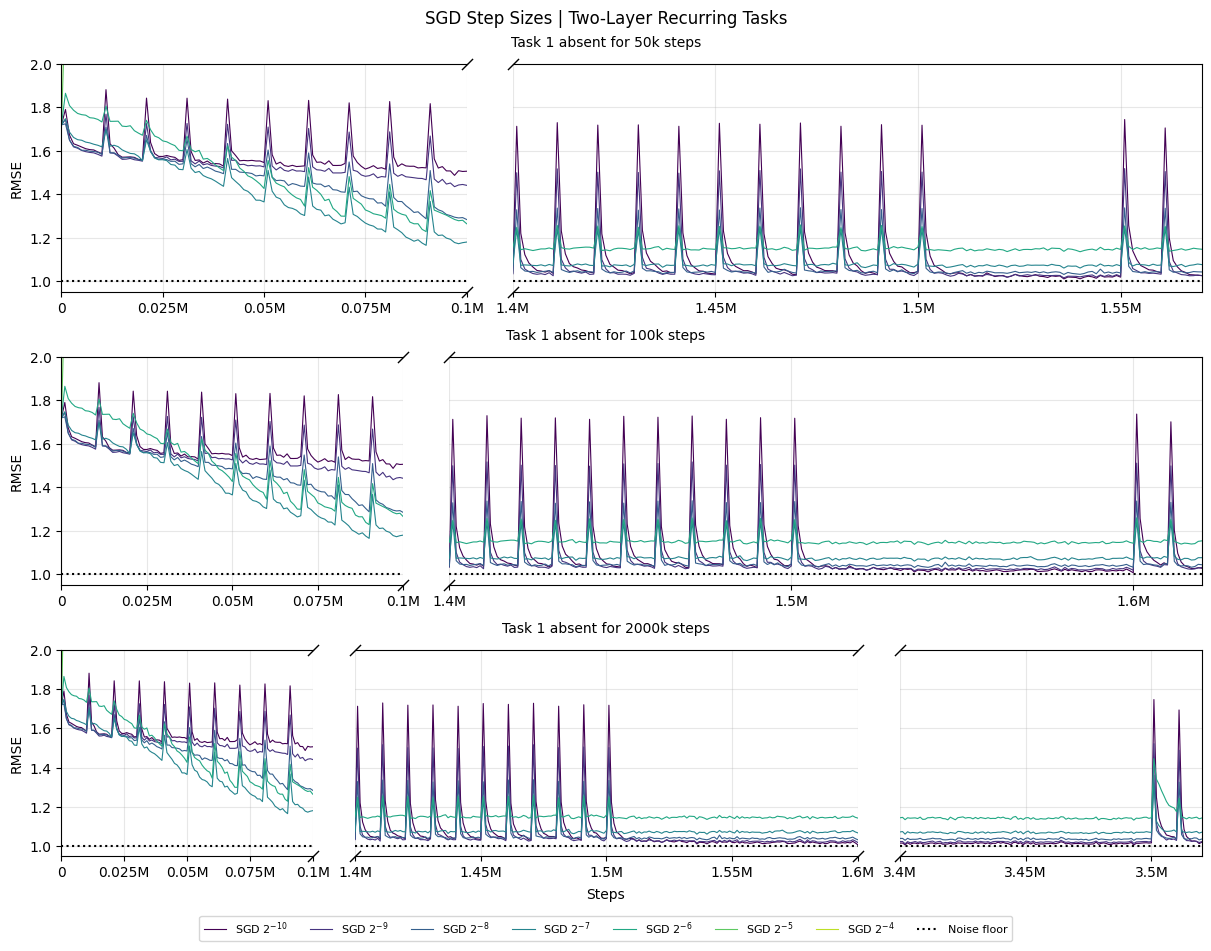

In [6]:
rates = 2. ** np.array(SGD_EXPONENTS)
tile = lambda a: jnp.tile(a, (len(rates),) + (1,) * (a.ndim - 1))  # lane = rate index * N_SEEDS + seed
learners = jax.vmap(partial(init_learner, autostep=False))(learner_keys)
sgd = run_all(sgd_step, (jax.tree.map(tile, learners), jnp.repeat(rates, N_SEEDS)), tile(data_keys), jax.tree.map(tile, teachers))
sgd = [curve.reshape(len(rates), N_SEEDS, -1) for curve in sgd]

final = np.mean([curve[:, :, -2 * PERIOD // WINDOW:].mean(axis=(1, 2)) for curve in sgd], axis=0)
best = int(np.argmin(np.where(np.isfinite(final), final, np.inf)))
print('Final-20k RMSE:', ', '.join(f'2^{p}: {v:.3f}' for p, v in zip(SGD_EXPONENTS, final)))
print(f'Chosen step size: 2^{SGD_EXPONENTS[best]}')
plot_runs(sgd, [f'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS], plt.cm.viridis(np.linspace(0, .9, len(rates))),
          'SGD Step Sizes | Two-Layer Recurring Tasks')

## SGD, Autostep and baseline

The SGD curve is the chosen sweep curve, not a new run. Autostep and both baselines see the same inputs and noise.

Runtime: 102.5s


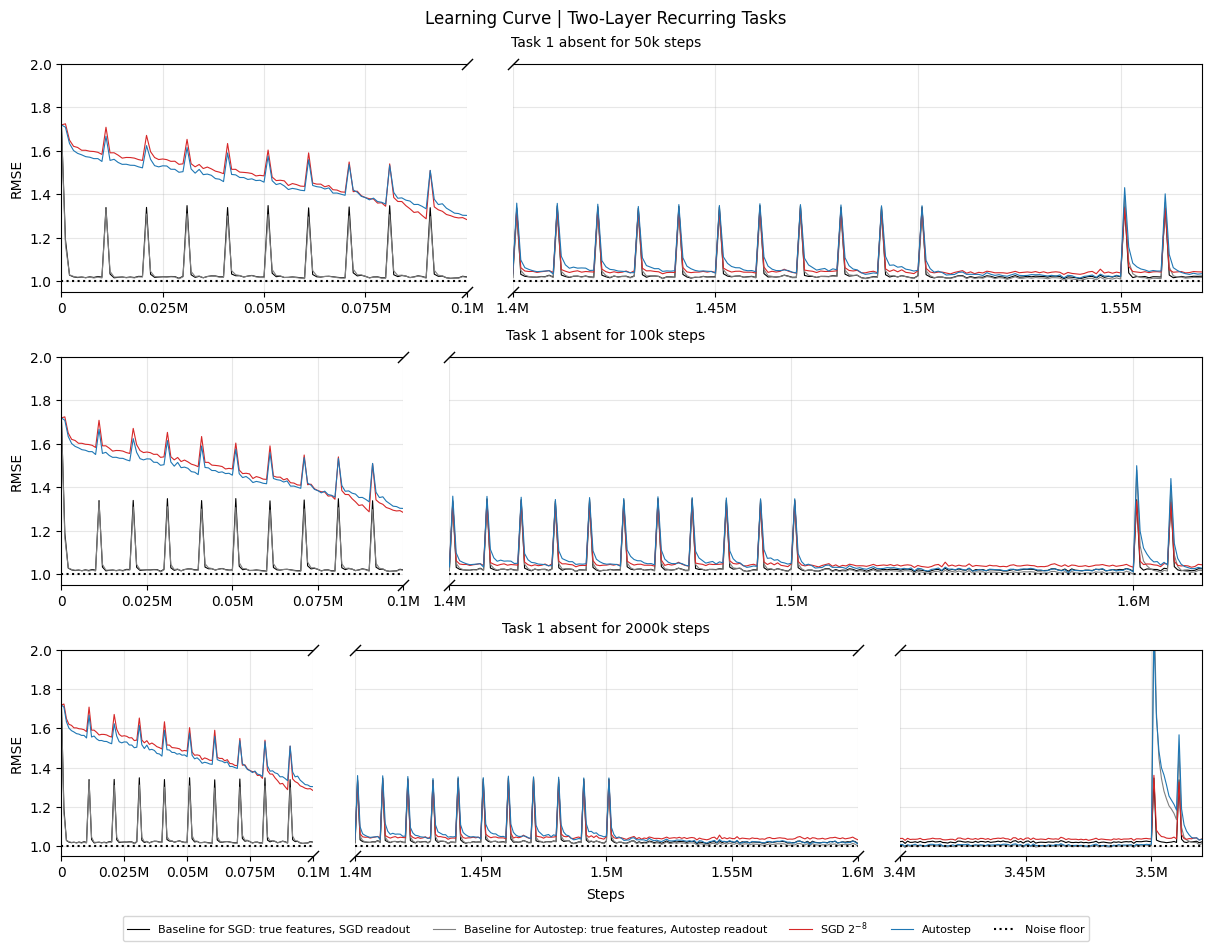

In [7]:
def autostep_and_baselines(state, x, y, teacher):
    learner, sgd_baseline, autostep_baseline = state
    learner, autostep_error = autostep_step(learner, x, y, teacher)
    sgd_baseline, sgd_baseline_error = baseline_step(sgd_baseline, x, y, teacher)
    autostep_baseline, autostep_baseline_error = autostep_baseline_step(autostep_baseline, x, y, teacher)
    return (learner, sgd_baseline, autostep_baseline), jnp.stack([autostep_error, sgd_baseline_error, autostep_baseline_error])


states = (jax.vmap(partial(init_learner, autostep=True))(learner_keys),
          jax.vmap(partial(init_baseline, rate=rates[best]))(teachers),
          jax.vmap(init_autostep_baseline)(teachers))
autostep, sgd_baseline, autostep_baseline = zip(*[np.moveaxis(curve, -1, 0) for curve in
                                                  run_all(autostep_and_baselines, states, data_keys, teachers)])
plot_runs([np.stack([sb, ab, s[best], a]) for s, a, sb, ab in zip(sgd, autostep, sgd_baseline, autostep_baseline)],
          ['Baseline for SGD: true features, SGD readout', 'Baseline for Autostep: true features, Autostep readout',
           f'SGD $2^{{{SGD_EXPONENTS[best]}}}$', 'Autostep'],
          ['black', 'gray', 'tab:red', 'tab:blue'], 'Learning Curve | Two-Layer Recurring Tasks')

## Absent-task feature change

Rerun SGD (chosen step size) and Autostep with the same seeds and data, snapshotting both every 10k steps through the 500k absence. Hidden units are measured on 1000 fixed random inputs, through the current network, so layer-2 firing also reflects changes in layer 1. When task 1 leaves, each layer-2 unit is assigned to the task of the teacher upper LTU whose firing it best matches (largest |correlation|), and only units assigned to task 1 are kept. Layer-1 teacher features are shared by both tasks, so every layer-1 unit is kept. Units firing on fewer than 1% or more than 99% of the inputs at that time are left out. The curves are medians over units and seeds of each unit's |correlation| with its own firing when task 1 left.

Runtime: 92.8s
SGD layer-2 units kept per seed: [16 14 14 15 15]
Autostep layer-2 units kept per seed: [15 13 13 15 12]


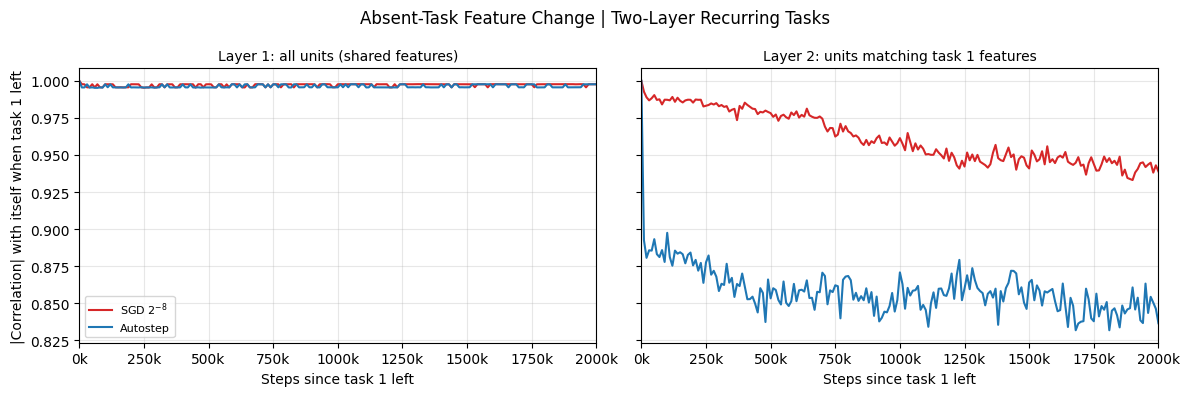

In [ ]:
PROBE = jax.random.rademacher(jax.random.PRNGKey(2), (1000, N_INPUTS), dtype=jnp.float32)
SNAPSHOT = 10_000


def sgd_and_autostep(state, x, y, teacher):
    sgd_state, learner = state
    sgd_state, sgd_error = sgd_step(sgd_state, x, y, teacher)
    learner, autostep_error = autostep_step(learner, x, y, teacher)
    return (sgd_state, learner), jnp.stack([sgd_error, autostep_error])


def hidden_firing(learner, inputs):
    """Firing of every hidden unit on each input: one (input, unit) array per layer."""
    a, layers = inputs, []
    for w, mean in zip(learner.weights[:-1], learner.means):
        bits = (a @ w[:, :-1].T + w[:, -1] > 0).astype(jnp.float32)
        layers.append(bits)
        a = (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))
    return layers


def zscore(a):  # over inputs, axis -2
    return (a - a.mean(-2, keepdims=True)) / (a.std(-2, keepdims=True) + 1e-8)


started = perf_counter()
simulate = jax.jit(jax.vmap(partial(run, sgd_and_autostep), in_axes=(0, 0, 0, None)))
measure = jax.jit(lambda states: [jax.vmap(hidden_firing, in_axes=(0, None))(learner, PROBE) for learner in (states[0][0], states[1])])
states = ((jax.vmap(partial(init_learner, autostep=False))(learner_keys), jnp.full(N_SEEDS, rates[best])),
          jax.vmap(partial(init_learner, autostep=True))(learner_keys))
states, keys, _, _ = simulate(states, data_keys, teachers, ACQUISITION_TASKS)
snapshots = [measure(states)]
for _ in range(ABSENCES[-1] // SNAPSHOT):  # task 0 only; task 1 is absent
    states, keys, _, _ = simulate(states, keys, teachers, np.zeros(SNAPSHOT // WINDOW, int))
    snapshots.append(measure(states))
print(f'Runtime: {perf_counter() - started:.1f}s')

teacher_upper = zscore(jax.vmap(lambda t: jax.vmap(lambda x: true_features(t, x).reshape(-1))(PROBE))(teachers))  # (seed, input, LTU)
medians = {}
for method in range(2):
    for layer in range(len(WIDTHS)):
        firing = np.stack([np.asarray(s[method][layer]) for s in snapshots])  # (snapshot, seed, input, unit)
        start = zscore(firing[0])
        correlation = np.abs(np.einsum('tspu,spu->tsu', zscore(firing), start)) / len(PROBE)
        rate = firing[0].mean(1)
        keep = (rate >= .01) & (rate <= .99)
        if layer == 1:
            closest = np.abs(np.einsum('spu,spl->sul', start, teacher_upper)).argmax(-1)
            keep &= closest // N_UPPER == 1
            print(['SGD', 'Autostep'][method], 'layer-2 units kept per seed:', keep.sum(1))
        medians[method, layer] = np.median(correlation[:, keep], axis=1)

steps = np.arange(len(snapshots)) * SNAPSHOT
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for layer, (ax, title) in enumerate(zip(axes, ('Layer 1: all units (shared features)', 'Layer 2: units matching task 1 features'))):
    for method, (label, color) in enumerate(((f'SGD $2^{{{SGD_EXPONENTS[best]}}}$', 'tab:red'), ('Autostep', 'tab:blue'))):
        ax.plot(steps, medians[method, layer], label=label, color=color)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, steps[-1])
    ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:g}k')
    ax.set_xlabel('Steps since task 1 left')
    ax.grid(True, alpha=.3)
axes[0].set_ylabel('|Correlation| with itself when task 1 left')
axes[0].legend(fontsize=8)
fig.suptitle('Absent-Task Feature Change | Two-Layer Recurring Tasks')
fig.tight_layout()
plt.show()

## Findings

Numbers below are from 1.5M steps of acquisition, Autostep meta step 0.02 and initial step 2⁻⁸, five seeds.

- **Both methods learn the shared representation.** SGD gets there faster.
- **Slow recovery after an absence comes from the readout, not lost features.** SGD recovers as fast as its SGD-readout baseline at every absence length. Autostep recovers more slowly, and more slowly the longer the absence, but its Autostep-readout baseline, with perfect frozen features, slows down in the same way. During the single-task stretch Autostep's readout reaches lower error, at the cost of slower re-adaptation after a switch. Over the 10k steps after task 1 returns, Autostep stays about 0.035 RMSE above its own baseline and SGD about 0.02 above its own, at every absence length.
- **Shared features stay stable; separate features drift slowly.** Layer-1 features, used by both tasks, keep a median |correlation| of about 0.996 with their state when task 1 left, throughout the 500k absence. The absent task's layer-2 features drift slowly even with sufficient capacity: 0.978 for SGD and 0.959 for Autostep after 500k steps. Over a 2M-step absence, Autostep's layer-2 features fell to about 0.95 and appeared to level off. 01a shows the same slow decline, to about 0.97 over 500k steps, for the absent teacher's units under Autostep with standardization.
- **Open:** the slow drift of features that serve only one task is not addressed here. It has not yet affected recovery measurably, so it is left until it does.